EXPERIMENT 1

Found 3925 files belonging to 10 classes.
Classes: ['n01440764', 'n02102040', 'n02979186', 'n03000684', 'n03028079', 'n03394916', 'n03417042', 'n03425413', 'n03445777', 'n03888257']
Original shape: (5, 224, 224, 3)
Preprocessed shape: (5, 224, 224, 3)


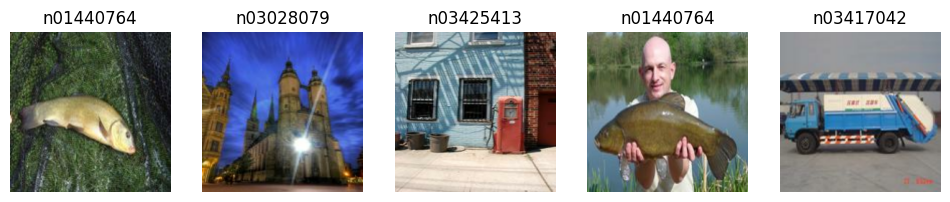

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 25s 0us/step
Pixel value before preprocessing: tf.Tensor([42. 41. 13.], shape=(3,), dtype=float32)
Pixel value after preprocessing : tf.Tensor([-90.939 -75.779 -81.68 ], shape=(3,), dtype=float32)
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step

Image 1
Original label: n01440764
Top-5 predictions:
tench n01440764 : 94.41 %
slug n01945685 : 5.1 %
bolete n13054560 : 0.23 %
weasel n02441942 : 0.08 %
eel n02526121 : 0.04 %
Predicted label: tench

Image 2
Original label: n03028079
Top-5 predictions:
fountain n03388043 : 48.77 %
church n03028079 : 21.23 %
palace n03877845 : 13.07 %
castle n02980441 : 5.32 %
stupa n04346328 : 2.04 %
Predicted label: fountain

Image 3
Original label: n03425413
Top-5 predictions:
gas_pump n03425413 : 56.36 %
mailbox n03710193 : 6.9 %
cinema n03032252 : 6.61 %
streetcar n04335435 : 3.17 %
barbershop n02791270 : 2.87 %
Predicted label: gas_pump

Image 4
Original label: n01440764
Top-5 predi

In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input, decode_predictions

# Download Imagenette
url = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz"

archive = tf.keras.utils.get_file(
    "imagenette2-160.tgz",
    url,
    untar=True
)

# Load validation images
dataset = tf.keras.utils.image_dataset_from_directory(
    archive + "/imagenette2-160/val",
    image_size=(224, 224),
    batch_size=5,
    shuffle=True
)

print("Classes:", dataset.class_names)

# Get 5 images
images, labels = next(iter(dataset))

print("Original shape:", images.shape)
print("Preprocessed shape: (5, 224, 224, 3)")

# Display images and original labels
plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(dataset.class_names[labels[i]])
    plt.axis("off")

plt.show()

# Load pretrained VGG16
model = VGG16(weights="imagenet")

# Preprocess images
x = preprocess_input(images)

# Show preprocessed representation
print("Pixel value before preprocessing:", images[0][0][0])
print("Pixel value after preprocessing :", x[0][0][0])

# Predict
predictions = model.predict(x)

# Top 5 predictions
results = decode_predictions(predictions, top=5)

# Display predictions and compare with original labels
for i in range(5):
    print("\nImage", i + 1)
    print("Original label:", dataset.class_names[labels[i]])
    print("Top-5 predictions:")

    for _, label, probability in results[i]:
        print(label,_, ":", round(probability * 100, 2), "%")

    print("Predicted label:", results[i][0][1])

**EXPERIMENT 2**

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 619ms/step
block1_conv1 shape: (1, 224, 224, 64)


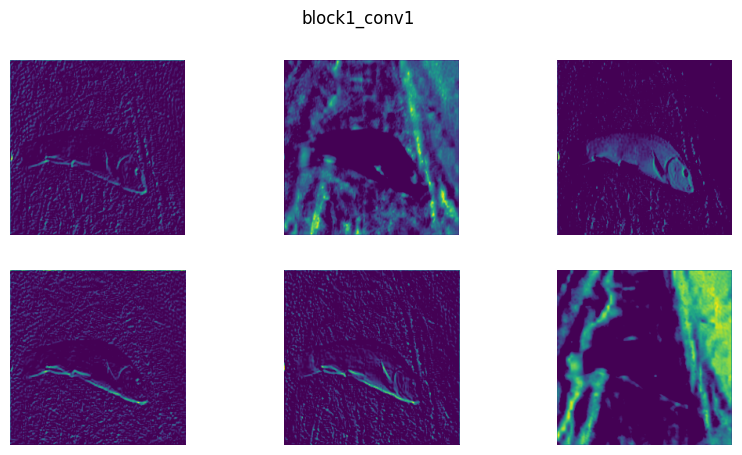

block2_conv2 shape: (1, 112, 112, 128)


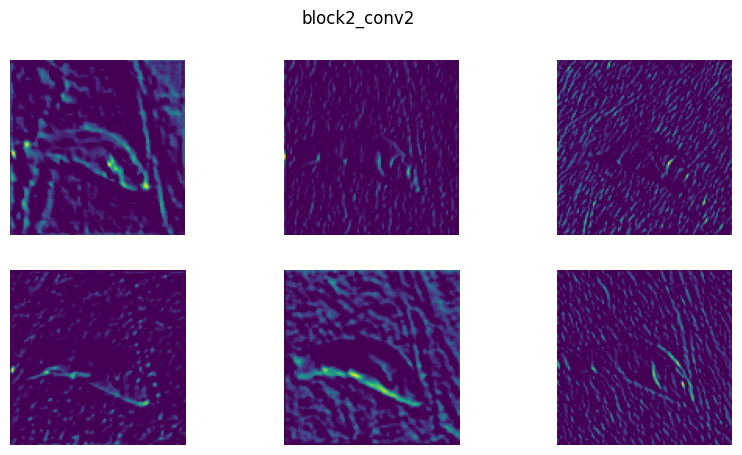

block5_conv3 shape: (1, 14, 14, 512)


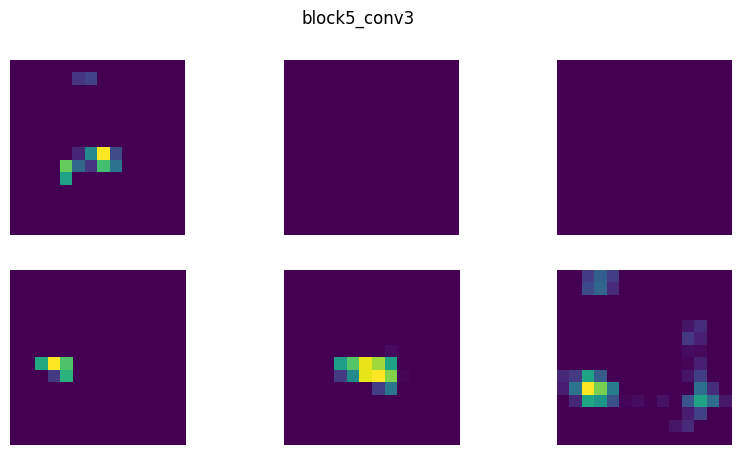

Filter shape: (3, 3, 3, 64)


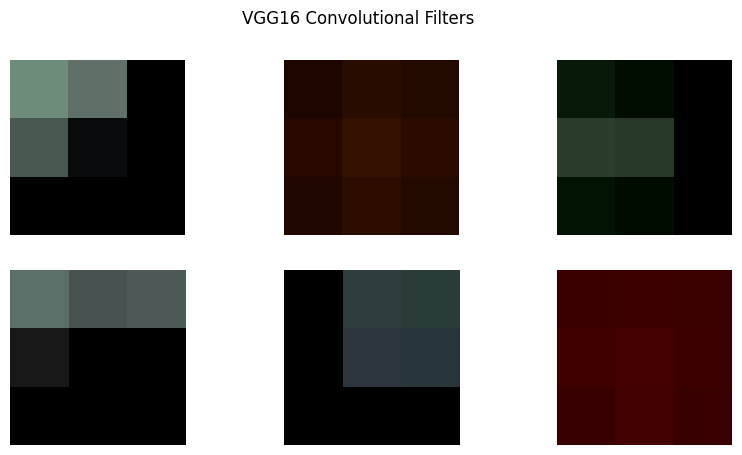

In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

# Load VGG16
model = VGG16(weights="imagenet")

# Take one image
image = images[0:1]
x = preprocess_input(image)

# Select 3 layers
layers = ["block1_conv1", "block2_conv2", "block5_conv3"]

# Create model to get feature maps
feature_model = tf.keras.Model(
    inputs=model.input,
    outputs=[model.get_layer(layer).output for layer in layers]
)

features = feature_model.predict(x)

# Display feature maps
for layer, feature in zip(layers, features):

    print(layer, "shape:", feature.shape)

    plt.figure(figsize=(10, 5))

    for i in range(6):
        plt.subplot(2, 3, i + 1)
        plt.imshow(feature[0, :, :, i], cmap="viridis")
        plt.axis("off")

    plt.suptitle(layer)
    plt.show()

# Display filters from first convolutional layer
filters = model.get_layer("block1_conv1").get_weights()[0]

print("Filter shape:", filters.shape)

plt.figure(figsize=(10, 5))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(filters[:, :, :, i])
    plt.axis("off")

plt.suptitle("VGG16 Convolutional Filters")
plt.show()

EXPERIMENT 3

In [9]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.models import Sequential
from sklearn.metrics import confusion_matrix, classification_report

# Load only a small dataset
train = tf.keras.utils.image_dataset_from_directory(
    archive + "/imagenette2-160/train",
    image_size=(224, 224),
    batch_size=20,
    shuffle=True
).take(10)

test = tf.keras.utils.image_dataset_from_directory(
    archive + "/imagenette2-160/val",
    image_size=(224, 224),
    batch_size=20,
    shuffle=True
).take(3)

# Preprocess
train = train.map(lambda x, y: (preprocess_input(x), y))
test = test.map(lambda x, y: (preprocess_input(x), y))

# VGG16 feature extractor
base = VGG16(weights="imagenet", include_top=False)
print("Feature map shape:", base.output.shape)
base.trainable = False

# Classifier
model = Sequential([
    base,
    GlobalAveragePooling2D(),
    Dense(10, activation="softmax")
])
print("Feature vector size: 512")

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train
model.fit(train, epochs=1)

# Test
y_true = []
y_pred = []

for x, y in test:
    pred = model.predict(x, verbose=0)
    y_true.extend(y.numpy())
    y_pred.extend(np.argmax(pred, axis=1))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nAccuracy, Precision, Recall and F1:")
print(classification_report(y_true, y_pred))

Found 9469 files belonging to 10 classes.
Found 3925 files belonging to 10 classes.
Feature map shape: (None, None, None, 512)
Feature vector size: 512
10/10 ━━━━━━━━━━━━━━━━━━━━ 104s 10s/step - accuracy: 0.1950 - loss: 6.3997
Confusion Matrix:
[[0 2 0 1 0 2 1 0 0 0]
 [3 1 0 0 0 2 0 0 0 0]
 [0 0 1 0 0 0 0 3 3 0]
 [0 0 0 0 0 3 3 0 0 0]
 [0 0 0 0 3 2 0 0 0 0]
 [0 1 0 0 1 0 1 0 1 0]
 [0 0 1 0 1 0 2 0 0 0]
 [1 0 1 0 0 1 0 1 0 0]
 [0 1 0 0 1 1 0 2 3 1]
 [4 0 0 0 1 1 0 1 0 2]]

Accuracy, Precision, Recall and F1:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         6
           1       0.20      0.17      0.18         6
           2       0.33      0.14      0.20         7
           3       0.00      0.00      0.00         6
           4       0.43      0.60      0.50         5
           5       0.00      0.00      0.00         4
           6       0.29      0.50      0.36         4
           7       0.14      0.25      0.18         4


EXPERIMENT 4

In [ ]:
# EX 4 - Image Caption Generation using CNN + LSTM

import tensorflow as tf
import numpy as np
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Load Imagenette
url = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz"

archive = tf.keras.utils.get_file(
    "imagenette2-160.tgz", url, untar=True
)

data = tf.keras.utils.image_dataset_from_directory(
    archive + "/imagenette2-160/train",
    image_size=(224,224),
    batch_size=20,
    shuffle=True
).take(10)

classes = data.class_names

# CNN feature extractor
cnn = VGG16(weights="imagenet", include_top=False, pooling="avg")

images, labels = next(iter(data))
features = cnn.predict(preprocess_input(images))

# Create captions
captions = ["start a photo of a " + classes[y] + " end"
            for y in labels.numpy()]

# Tokenize
tokenizer = Tokenizer()
tokenizer.fit_on_texts(captions)

seq = tokenizer.texts_to_sequences(captions)
seq = pad_sequences(seq, padding="pre")

# LSTM
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(features.shape[1],)),
    tf.keras.layers.RepeatVector(seq.shape[1]),
    tf.keras.layers.LSTM(128),
    tf.keras.layers.Dense(len(tokenizer.word_index)+1, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy"
)

# Train
model.fit(features, seq[:, -1], epochs=5)

print("CNN feature shape:", features.shape)
print("Vocabulary:", tokenizer.word_index)
print("Expected Caption:", captions[0])

experiment 5

Generated image shape: (5, 64, 64, 3)
Discriminator output: [[0.99999756]
 [0.9999976 ]
 [0.9999977 ]
 [0.99999774]
 [0.99999774]]


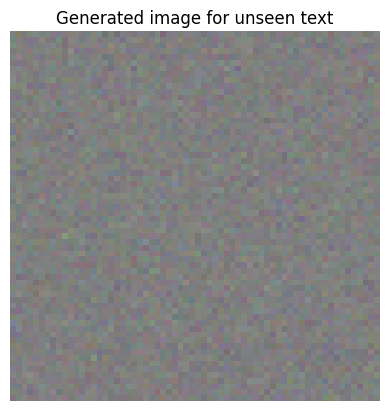

In [5]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers

# Text representation
texts = ["dog", "tiger", "bird", "truck", "church"]
text = np.eye(5)

# Generator: noise + text -> image
generator = tf.keras.Sequential([
    layers.Input(shape=(105,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64 * 64 * 3, activation="sigmoid"),
    layers.Reshape((64, 64, 3))
])

# Discriminator: image + text -> real/fake
image = layers.Input(shape=(64, 64, 3))
condition = layers.Input(shape=(5,))

x = layers.Flatten()(image)
x = layers.Concatenate()([x, condition])
x = layers.Dense(64, activation="relu")(x)
output = layers.Dense(1, activation="sigmoid")(x)

discriminator = tf.keras.Model([image, condition], output)

discriminator.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

# Random noise + text
noise = np.random.normal(0, 1, (5, 100))
fake_images = generator.predict(
    np.concatenate([noise, text], axis=1),
    verbose=0
)

# Train discriminator
real_images = np.random.random((5, 64, 64, 3))

discriminator.train_on_batch(
    [real_images, text],
    np.ones((5, 1))
)

discriminator.train_on_batch(
    [fake_images, text],
    np.zeros((5, 1))
)

print("Generated image shape:", fake_images.shape)
print("Discriminator output:",
      discriminator.predict([fake_images, text], verbose=0))

# Unseen text
new_text = np.array([[1, 0, 0, 0, 0]])
new_noise = np.random.normal(0, 1, (1, 100))

new_image = generator.predict(
    np.concatenate([new_noise, new_text], axis=1),
    verbose=0
)

plt.imshow(new_image[0])
plt.title("Generated image for unseen text")
plt.axis("off")
plt.show()

experiment 4 rizz

In [7]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

# Download Imagenette
url = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz"

archive = tf.keras.utils.get_file(
    "imagenette2-160.tgz",
    url,
    untar=True
)

# Load training images
train = tf.keras.utils.image_dataset_from_directory(
    archive + "/imagenette2-160/train",
    image_size=(224,224),
    batch_size=20,
    shuffle=False
)

test = tf.keras.utils.image_dataset_from_directory(
    archive + "/imagenette2-160/val",
    image_size=(224,224),
    batch_size=20,
    shuffle=False
)

classes = train.class_names

train = train.take(10)
test = test.take(3)

cnn = VGG16(
    weights="imagenet",
    include_top=False,
    pooling="avg"
)

train_images = np.concatenate([x.numpy() for x,y in train])
train_labels = np.concatenate([y.numpy() for x,y in train])

test_images = np.concatenate([x.numpy() for x,y in test])
test_labels = np.concatenate([y.numpy() for x,y in test])

train_features = cnn.predict(preprocess_input(train_images))
test_features = cnn.predict(preprocess_input(test_images))

print("CNN Feature Vector:", train_features.shape)

X = train_features.reshape(
    train_features.shape[0],
    1,
    train_features.shape[1]
)

model = tf.keras.Sequential([
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dense(len(classes), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(X, train_labels, epochs=10)

test_X = test_features.reshape(
    test_features.shape[0],
    1,
    test_features.shape[1]
)

pred = model.predict(test_X)

for i in range(min(5, len(pred))):

    predicted_class = classes[np.argmax(pred[i])]

    expected = "A photo of a " + classes[test_labels[i]] + "."
    generated = "A photo of a " + predicted_class + "."

    print("Expected :", expected)
    print("Generated:", generated)
    print()

Found 9469 files belonging to 10 classes.
Found 3925 files belonging to 10 classes.
7/7 ━━━━━━━━━━━━━━━━━━━━ 104s 15s/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 30s 14s/step
CNN Feature Vector: (200, 512)
Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6850 - loss: 1.4643   
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 1.0000 - loss: 0.2025
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 0.0520 
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0281 
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0189 
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 0.0140 
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0111 
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0092 
Epoch 9/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0077 
Epoch 10/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy

EXPERIMENT 5 RIZZ

In [ ]:
# EX 5 - Conditional GAN

import tensorflow as tf
import matplotlib.pyplot as plt

SIZE = 64
NOISE = 100

# Download Imagenette
url = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz"

archive = tf.keras.utils.get_file(
    "imagenette2-160.tgz",
    url,
    untar=True
)

# Load dataset
data = tf.keras.utils.image_dataset_from_directory(
    archive + "/imagenette2-160/train",
    image_size=(SIZE, SIZE),
    batch_size=32
)

classes = data.class_names
n = len(classes)

# Generator
generator = tf.keras.Sequential([
    tf.keras.layers.Input((NOISE + n,)),
    tf.keras.layers.Dense(8*8*128),
    tf.keras.layers.Reshape((8,8,128)),
    tf.keras.layers.Conv2DTranspose(64, 4, 2, padding="same", activation="relu"),
    tf.keras.layers.Conv2DTranspose(32, 4, 2, padding="same", activation="relu"),
    tf.keras.layers.Conv2DTranspose(3, 4, 2, padding="same", activation="tanh")
])

# Discriminator
discriminator = tf.keras.Sequential([
    tf.keras.layers.Input((SIZE, SIZE, 3+n)),
    tf.keras.layers.Conv2D(64, 4, 2, padding="same"),
    tf.keras.layers.LeakyReLU(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1)
])

# Generate image from text
class_id = 0
text = tf.one_hot([class_id], n)
noise = tf.random.normal((1, NOISE))

generated = generator(
    tf.concat([noise, text], axis=1)
)

image = (generated[0] + 1) / 2

print("Text: A photo of a", classes[class_id])

plt.imshow(image)
plt.title("Generated " + classes[class_id])
plt.axis("off")
plt.show()